In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Load the dataset
df = pd.read_csv('AEP_hourly.csv')

print("Shape:", df.shape)
print("\nColumn names:", df.columns.tolist())
print("\nFirst 5 rows:")
print(df.head())

Shape: (121273, 2)

Column names: ['Datetime', 'AEP_MW']

First 5 rows:
              Datetime   AEP_MW
0  2004-12-31 01:00:00  13478.0
1  2004-12-31 02:00:00  12865.0
2  2004-12-31 03:00:00  12577.0
3  2004-12-31 04:00:00  12517.0
4  2004-12-31 05:00:00  12670.0


Data type of index: datetime64[us]

Date range:
Start: 2004-10-01 01:00:00
End: 2018-08-03 00:00:00

Total hours of data: 121273


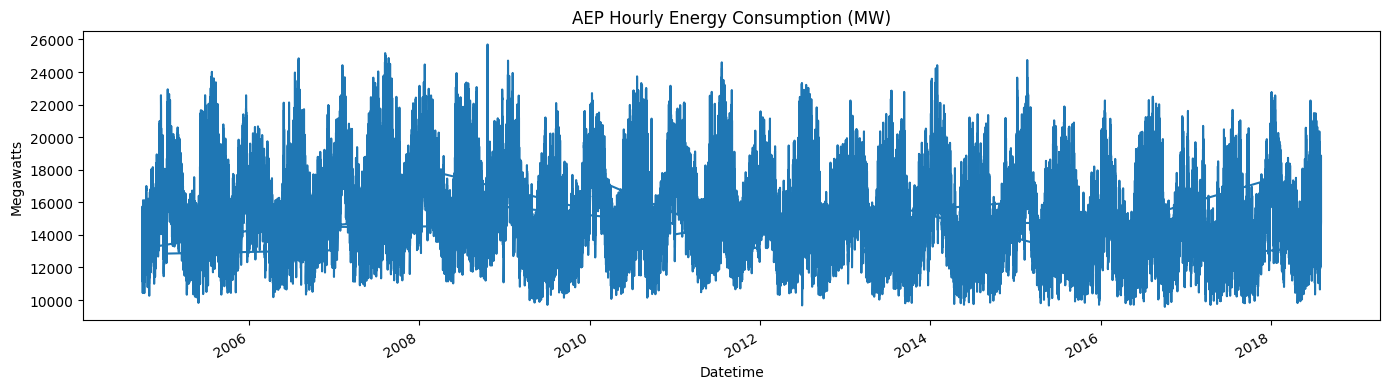

In [2]:
# Convert Datetime column to proper datetime format
df['Datetime'] = pd.to_datetime(df['Datetime'])

# Set Datetime as the index
df = df.set_index('Datetime')

print("Data type of index:", df.index.dtype)
print("\nDate range:")
print("Start:", df.index.min())
print("End:", df.index.max())
print("\nTotal hours of data:", len(df))

# Plot the full dataset
df['AEP_MW'].plot(figsize=(14, 4), title='AEP Hourly Energy Consumption (MW)')
plt.ylabel('Megawatts')
plt.tight_layout()
plt.show()

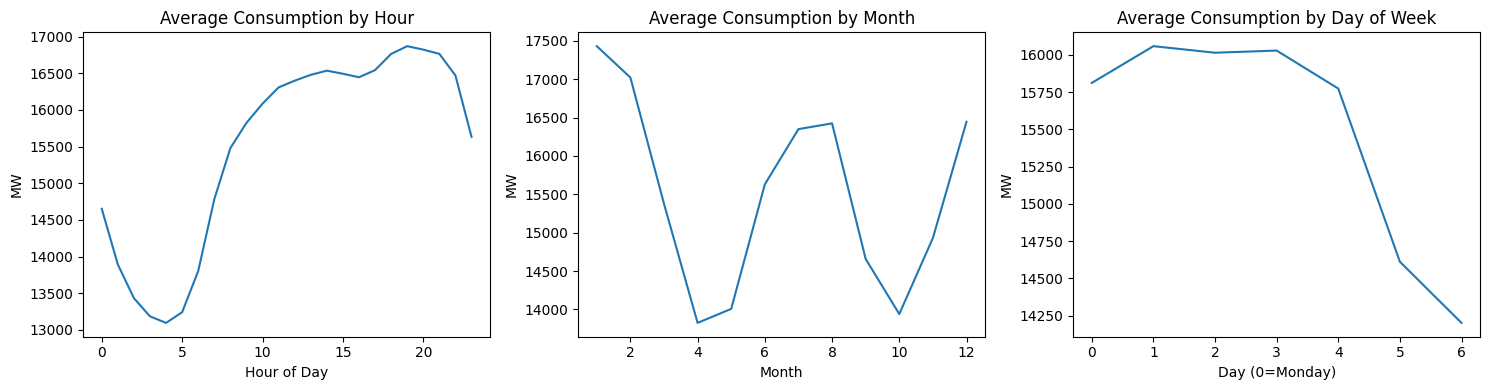

In [3]:
# Extract time features
df['hour'] = df.index.hour
df['month'] = df.index.month
df['dayofweek'] = df.index.dayofweek

# Plot average consumption by hour
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

df.groupby('hour')['AEP_MW'].mean().plot(ax=axes[0])
axes[0].set_title('Average Consumption by Hour')
axes[0].set_xlabel('Hour of Day')
axes[0].set_ylabel('MW')

df.groupby('month')['AEP_MW'].mean().plot(ax=axes[1])
axes[1].set_title('Average Consumption by Month')
axes[1].set_xlabel('Month')
axes[1].set_ylabel('MW')

df.groupby('dayofweek')['AEP_MW'].mean().plot(ax=axes[2])
axes[2].set_title('Average Consumption by Day of Week')
axes[2].set_xlabel('Day (0=Monday)')
axes[2].set_ylabel('MW')

plt.tight_layout()
plt.show()

In [4]:
# Feature engineering - extract time features for the model
def create_features(df):
    df = df.copy()
    df['hour'] = df.index.hour
    df['dayofweek'] = df.index.dayofweek
    df['month'] = df.index.month
    df['quarter'] = df.index.quarter
    df['year'] = df.index.year
    df['dayofyear'] = df.index.dayofyear
    return df

df = create_features(df)

# Define features and target
X = df[['hour', 'dayofweek', 'month', 'quarter', 'year', 'dayofyear']]
y = df['AEP_MW']

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nSample features:")
print(X.head())

Features shape: (121273, 6)
Target shape: (121273,)

Sample features:
                     hour  dayofweek  month  quarter  year  dayofyear
Datetime                                                             
2004-12-31 01:00:00     1          4     12        4  2004        366
2004-12-31 02:00:00     2          4     12        4  2004        366
2004-12-31 03:00:00     3          4     12        4  2004        366
2004-12-31 04:00:00     4          4     12        4  2004        366
2004-12-31 05:00:00     5          4     12        4  2004        366


In [5]:
# For time series we split by time, not randomly!
# Use data before 2015 for training, 2015 onwards for testing
train = df[df.index.year < 2015]
test = df[df.index.year >= 2015]

X_train = train[['hour', 'dayofweek', 'month', 'quarter', 'year', 'dayofyear']]
y_train = train['AEP_MW']
X_test = test[['hour', 'dayofweek', 'month', 'quarter', 'year', 'dayofyear']]
y_test = test['AEP_MW']

print("Training size:", X_train.shape)
print("Testing size:", X_test.shape)
print("\nTraining period:", train.index.min(), "to", train.index.max())
print("Testing period:", test.index.min(), "to", test.index.max())

Training size: (89833, 6)
Testing size: (31440, 6)

Training period: 2004-10-01 01:00:00 to 2014-12-31 23:00:00
Testing period: 2015-01-01 00:00:00 to 2018-08-03 00:00:00


In [6]:
import xgboost as xgb
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np

# Train XGBoost model
model = xgb.XGBRegressor(
    n_estimators=1000,
    learning_rate=0.01,
    max_depth=5,
    random_state=42
)

model.fit(X_train, y_train,
          eval_set=[(X_train, y_train), (X_test, y_test)],
          verbose=100)

print("Model trained!")

[0]	validation_0-rmse:2559.11854	validation_1-rmse:2671.53463
[100]	validation_0-rmse:1764.04608	validation_1-rmse:1985.15137
[200]	validation_0-rmse:1473.17775	validation_1-rmse:1759.37466
[300]	validation_0-rmse:1344.98733	validation_1-rmse:1687.92740
[400]	validation_0-rmse:1252.89073	validation_1-rmse:1649.62228
[500]	validation_0-rmse:1198.71401	validation_1-rmse:1640.35455
[600]	validation_0-rmse:1167.76407	validation_1-rmse:1639.41367
[700]	validation_0-rmse:1143.84281	validation_1-rmse:1649.93166
[800]	validation_0-rmse:1122.44580	validation_1-rmse:1658.61397
[900]	validation_0-rmse:1105.02683	validation_1-rmse:1662.40554
[999]	validation_0-rmse:1087.73609	validation_1-rmse:1668.52464
Model trained!


RMSE: 1668.52 MW
MAE: 1297.03 MW


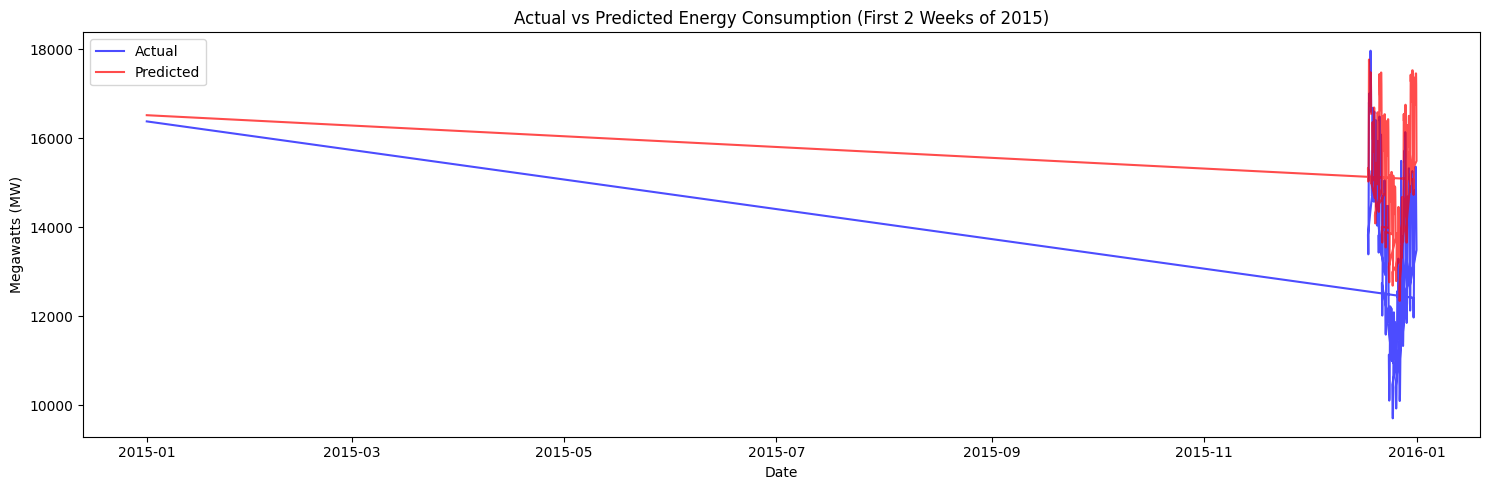

In [7]:
# Make predictions
y_pred = model.predict(X_test)

# Calculate error metrics
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)

print(f"RMSE: {rmse:.2f} MW")
print(f"MAE: {mae:.2f} MW")

# Plot actual vs predicted for first 2 weeks
plt.figure(figsize=(15, 5))
plt.plot(y_test.index[:336], y_test.values[:336], label='Actual', color='blue', alpha=0.7)
plt.plot(y_test.index[:336], y_pred[:336], label='Predicted', color='red', alpha=0.7)
plt.title('Actual vs Predicted Energy Consumption (First 2 Weeks of 2015)')
plt.xlabel('Date')
plt.ylabel('Megawatts (MW)')
plt.legend()
plt.tight_layout()
plt.show()

RMSE: 1668.52 MW
MAE: 1297.03 MW


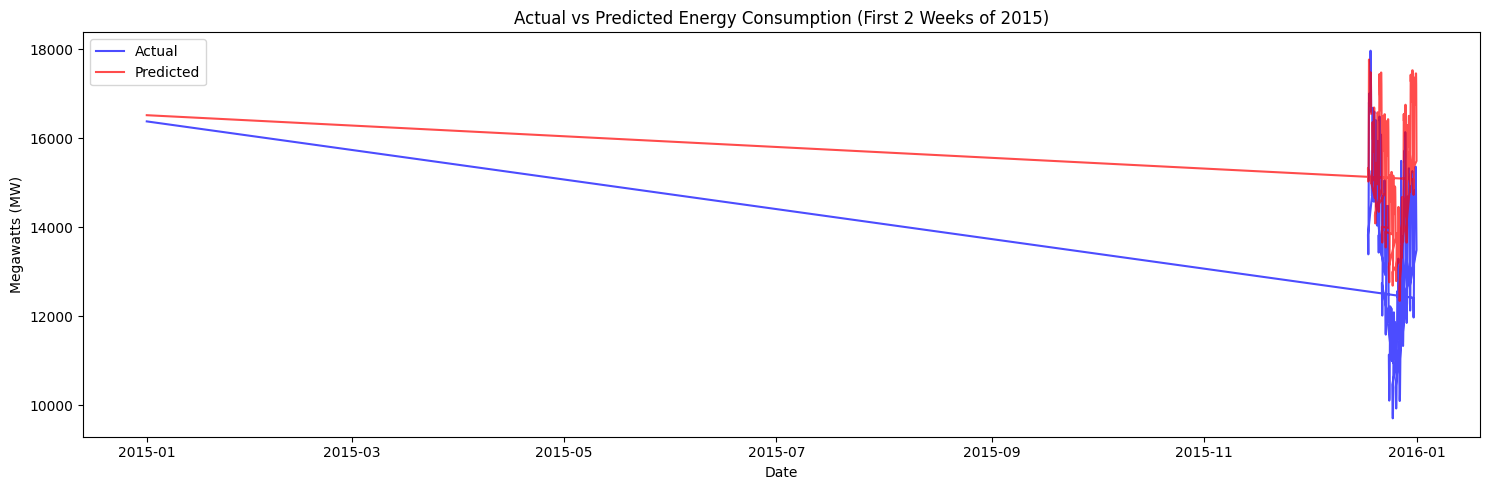

In [8]:
# Make predictions
y_pred = model.predict(X_test)

# Calculate error metrics
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)

print(f"RMSE: {rmse:.2f} MW")
print(f"MAE: {mae:.2f} MW")

# Plot actual vs predicted for first 2 weeks
plt.figure(figsize=(15, 5))
plt.plot(y_test.index[:336], y_test.values[:336], label='Actual', color='blue', alpha=0.7)
plt.plot(y_test.index[:336], y_pred[:336], label='Predicted', color='red', alpha=0.7)
plt.title('Actual vs Predicted Energy Consumption (First 2 Weeks of 2015)')
plt.xlabel('Date')
plt.ylabel('Megawatts (MW)')
plt.legend()
plt.tight_layout()
plt.show()

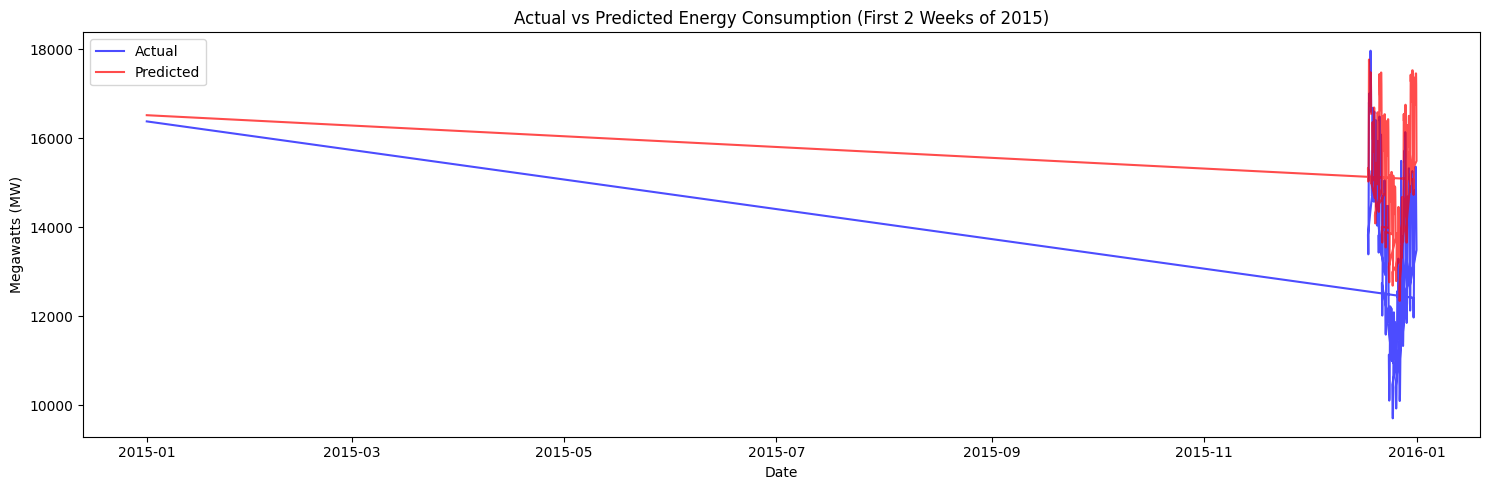

In [9]:
# Plot just first 2 weeks (336 hours = 14 days * 24 hours)
test_2weeks = y_test.iloc[:336]
pred_2weeks = y_pred[:336]

plt.figure(figsize=(15, 5))
plt.plot(test_2weeks.index, test_2weeks.values, label='Actual', color='blue', alpha=0.7)
plt.plot(test_2weeks.index, pred_2weeks, label='Predicted', color='red', alpha=0.7)
plt.title('Actual vs Predicted Energy Consumption (First 2 Weeks of 2015)')
plt.xlabel('Date')
plt.ylabel('Megawatts (MW)')
plt.legend()
plt.tight_layout()
plt.show()

RMSE: 1808.12 MW
MAE: 1461.59 MW


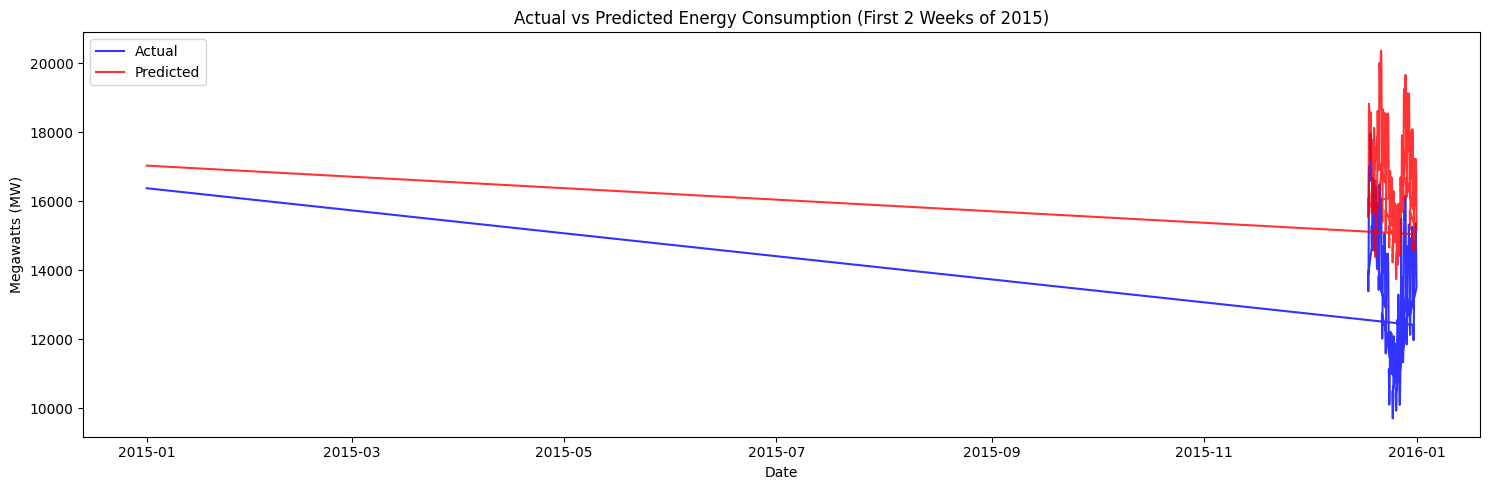

In [10]:
import xgboost as xgb
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Remove year feature - it causes the model to follow trend not patterns
X_train2 = X_train[['hour', 'dayofweek', 'month', 'quarter', 'dayofyear']]
X_test2 = X_test[['hour', 'dayofweek', 'month', 'quarter', 'dayofyear']]

model2 = xgb.XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    random_state=42
)

model2.fit(X_train2, y_train)
y_pred2 = model2.predict(X_test2)

rmse2 = np.sqrt(mean_squared_error(y_test, y_pred2))
mae2 = mean_absolute_error(y_test, y_pred2)
print(f"RMSE: {rmse2:.2f} MW")
print(f"MAE: {mae2:.2f} MW")

# Plot first 2 weeks properly
plt.figure(figsize=(15, 5))
plt.plot(y_test.iloc[:336].index, y_test.iloc[:336].values, 
         label='Actual', color='blue', alpha=0.8)
plt.plot(y_test.iloc[:336].index, y_pred2[:336], 
         label='Predicted', color='red', alpha=0.8)
plt.title('Actual vs Predicted Energy Consumption (First 2 Weeks of 2015)')
plt.xlabel('Date')
plt.ylabel('Megawatts (MW)')
plt.legend()
plt.tight_layout()
plt.show()

RMSE: 980.61 MW
MAE: 727.96 MW


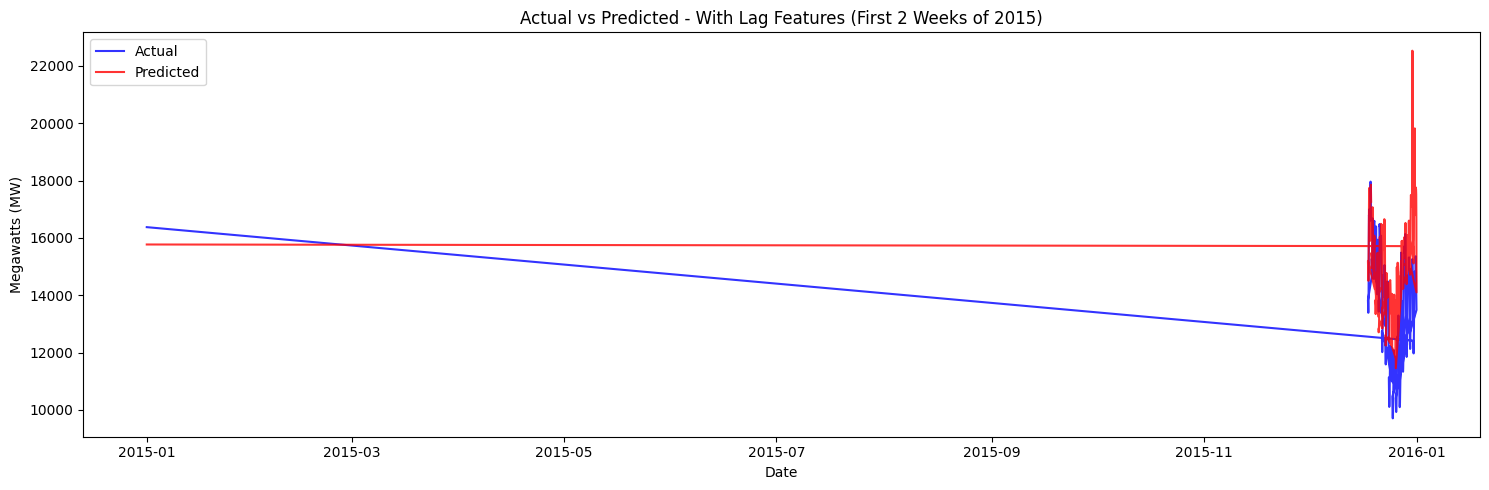

In [11]:
# Add lag features - previous consumption as input
df['lag_24'] = df['AEP_MW'].shift(24)   # consumption 24 hours ago
df['lag_48'] = df['AEP_MW'].shift(48)   # consumption 48 hours ago  
df['lag_168'] = df['AEP_MW'].shift(168) # consumption 1 week ago

# Drop rows with NaN from lag
df = df.dropna()

# Redefine features with lags
features = ['hour', 'dayofweek', 'month', 'quarter', 'dayofyear', 
            'lag_24', 'lag_48', 'lag_168']

train = df[df.index.year < 2015]
test = df[df.index.year >= 2015]

X_train = train[features]
y_train = train['AEP_MW']
X_test = test[features]
y_test = test['AEP_MW']

# Retrain
model3 = xgb.XGBRegressor(n_estimators=500, learning_rate=0.05, 
                           max_depth=6, random_state=42)
model3.fit(X_train, y_train)
y_pred3 = model3.predict(X_test)

rmse3 = np.sqrt(mean_squared_error(y_test, y_pred3))
mae3 = mean_absolute_error(y_test, y_pred3)
print(f"RMSE: {rmse3:.2f} MW")
print(f"MAE: {mae3:.2f} MW")

# Plot first 2 weeks
plt.figure(figsize=(15, 5))
plt.plot(y_test.iloc[:336].index, y_test.iloc[:336].values,
         label='Actual', color='blue', alpha=0.8)
plt.plot(y_test.iloc[:336].index, y_pred3[:336],
         label='Predicted', color='red', alpha=0.8)
plt.title('Actual vs Predicted - With Lag Features (First 2 Weeks of 2015)')
plt.xlabel('Date')
plt.ylabel('Megawatts (MW)')
plt.legend()
plt.tight_layout()
plt.show()

In [12]:
# Filter explicitly to January 2015 only
jan_2015_actual = y_test['2015-01-01':'2015-01-14']
jan_2015_pred = y_pred3[y_test.index.get_loc('2015-01-01'):
                         y_test.index.get_loc('2015-01-01') + len(jan_2015_actual)]

plt.figure(figsize=(15, 5))
plt.plot(jan_2015_actual.index, jan_2015_actual.values,
         label='Actual', color='blue', alpha=0.8)
plt.plot(jan_2015_actual.index, jan_2015_pred,
         label='Predicted', color='red', alpha=0.8)
plt.title('Actual vs Predicted - First 2 Weeks of January 2015')
plt.xlabel('Date')
plt.ylabel('Megawatts (MW)')
plt.legend()
plt.tight_layout()
plt.show()

KeyError: 'Value based partial slicing on non-monotonic DatetimeIndexes with non-existing keys is not allowed.'

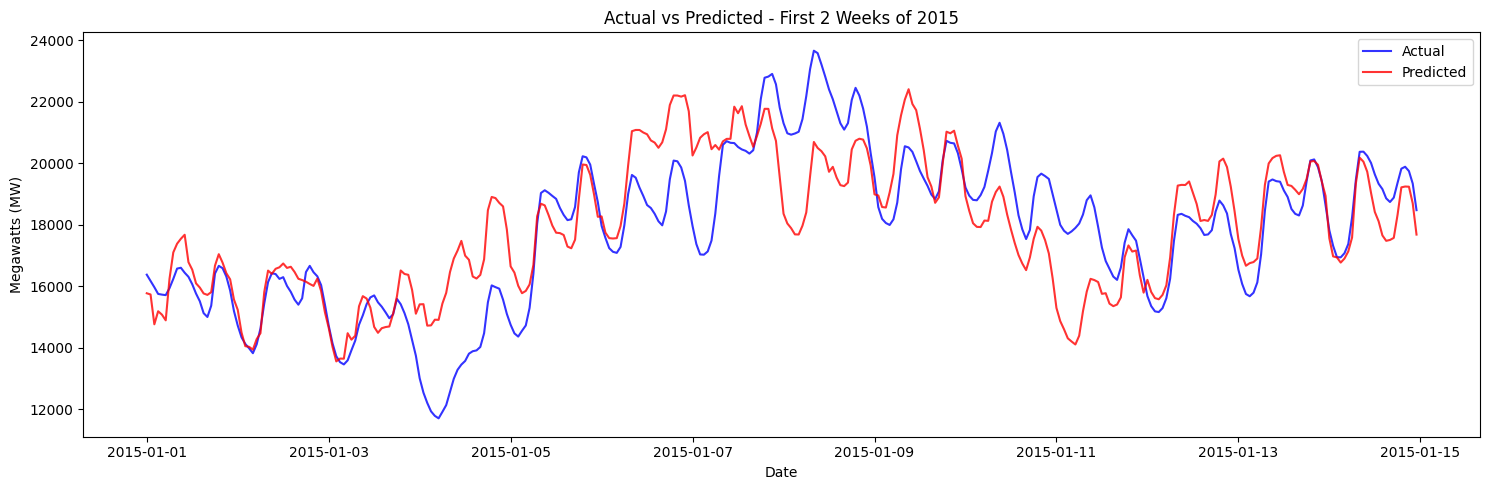

In [13]:
# Sort index first then plot
y_test_sorted = y_test.sort_index()
y_pred_series = pd.Series(y_pred3, index=y_test.index).sort_index()

# Get first 336 rows (2 weeks)
actual_2weeks = y_test_sorted.iloc[:336]
pred_2weeks = y_pred_series.iloc[:336]

plt.figure(figsize=(15, 5))
plt.plot(actual_2weeks.index, actual_2weeks.values,
         label='Actual', color='blue', alpha=0.8)
plt.plot(pred_2weeks.index, pred_2weeks.values,
         label='Predicted', color='red', alpha=0.8)
plt.title('Actual vs Predicted - First 2 Weeks of 2015')
plt.xlabel('Date')
plt.ylabel('Megawatts (MW)')
plt.legend()
plt.tight_layout()
plt.show()

In [14]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from sklearn.preprocessing import MinMaxScaler
import numpy as np

# Scale data - LSTM needs values between 0 and 1
scaler = MinMaxScaler()
scaled_data = scaler.fit_transform(df[['AEP_MW']])

# Create sequences
def create_sequences(data, timesteps=24):
    X, y = [], []
    for i in range(timesteps, len(data)):
        X.append(data[i-timesteps:i, 0])
        y.append(data[i, 0])
    return np.array(X), np.array(y)

timesteps = 24
X_seq, y_seq = create_sequences(scaled_data, timesteps)

# Reshape for LSTM: (samples, timesteps, features)
X_seq = X_seq.reshape(X_seq.shape[0], X_seq.shape[1], 1)

print("X shape:", X_seq.shape)
print("y shape:", y_seq.shape)

X shape: (121081, 24, 1)
y shape: (121081,)


In [15]:
# Split by time - same logic as XGBoost, no data leakage
# Find where 2015 starts in our sequence
train_size = len(df[df.index.year < 2015]) - timesteps
X_train_seq = X_seq[:train_size]
y_train_seq = y_seq[:train_size]
X_test_seq = X_seq[train_size:]
y_test_seq = y_seq[train_size:]

print("Training samples:", X_train_seq.shape[0])
print("Testing samples:", X_test_seq.shape[0])

# Build LSTM model
model_lstm = Sequential([
    LSTM(64, return_sequences=True, input_shape=(timesteps, 1)),
    Dropout(0.2),
    LSTM(32, return_sequences=False),
    Dropout(0.2),
    Dense(1)
])

model_lstm.summary()

Training samples: 89641
Testing samples: 31440


/opt/miniconda3/lib/python3.13/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 24, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,345 (114.63 KB)

 Trainable params: 29,345 (114.63 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:
from tensorflow.keras.callbacks import EarlyStopping

# Early stopping - stops training if no improvement for 3 epochs
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

# Train
history = model_lstm.fit(
    X_train_seq, y_train_seq,
    epochs=20,
    batch_size=32,
    validation_split=0.1,
    callbacks=[early_stop],
    verbose=1
)

print("Training complete!")

ValueError: You must call `compile()` before using the model.

In [17]:
model_lstm.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)
print("Model compiled!")
from tensorflow.keras.callbacks import EarlyStopping

# Early stopping - stops training if no improvement for 3 epochs
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

# Train
history = model_lstm.fit(
    X_train_seq, y_train_seq,
    epochs=20,
    batch_size=32,
    validation_split=0.1,
    callbacks=[early_stop],
    verbose=1
)

print("Training complete!")

Model compiled!
Epoch 1/20
2522/2522 ━━━━━━━━━━━━━━━━━━━━ 22s 8ms/step - loss: 0.0042 - mae: 0.0466 - val_loss: 0.0011 - val_mae: 0.0236
Epoch 2/20
2522/2522 ━━━━━━━━━━━━━━━━━━━━ 20s 8ms/step - loss: 0.0013 - mae: 0.0263 - val_loss: 9.3822e-04 - val_mae: 0.0216
Epoch 3/20
2522/2522 ━━━━━━━━━━━━━━━━━━━━ 20s 8ms/step - loss: 0.0010 - mae: 0.0232 - val_loss: 8.7948e-04 - val_mae: 0.0207
Epoch 4/20
2522/2522 ━━━━━━━━━━━━━━━━━━━━ 20s 8ms/step - loss: 9.5934e-04 - mae: 0.0221 - val_loss: 7.4795e-04 - val_mae: 0.0176
Epoch 5/20
2522/2522 ━━━━━━━━━━━━━━━━━━━━ 20s 8ms/step - loss: 9.1539e-04 - mae: 0.0216 - val_loss: 7.1111e-04 - val_mae: 0.0174
Epoch 6/20
2522/2522 ━━━━━━━━━━━━━━━━━━━━ 20s 8ms/step - loss: 8.5528e-04 - mae: 0.0208 - val_loss: 6.0614e-04 - val_mae: 0.0149
Epoch 7/20
2522/2522 ━━━━━━━━━━━━━━━━━━━━ 20s 8ms/step - loss: 8.3312e-04 - mae: 0.0205 - val_loss: 6.0605e-04 - val_mae: 0.0153
Epoch 8/20
2522/2522 ━━━━━━━━━━━━━━━━━━━━ 20s 8ms/step - loss: 8.0677e-04 - mae: 0.0202 - val_los